In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_validate, cross_val_predict, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

zoo = pd.read_csv("zoo.csv")
kelas = pd.read_csv("class.csv")

TARGET = "class_type"
NAMA_COL = "animal_name"

print("zoo  :", zoo.shape)
print("class:", kelas.shape)
display(zoo.head())
display(kelas[["Class_Number", "Number_Of_Animal_Species_In_Class", "Class_Type"]])

zoo  : (101, 18)
class: (7, 4)


,animal_name,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize,class_type
0,aardvark,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1
1,antelope,1,0,0,1,0,0,0,1,1,1,0,0,4,1,0,1,1
2,bass,0,0,1,0,0,1,1,1,1,0,0,1,0,1,0,0,4
3,bear,1,0,0,1,0,0,1,1,1,1,0,0,4,0,0,1,1
4,boar,1,0,0,1,0,0,1,1,1,1,0,0,4,1,0,1,1


,Class_Number,Number_Of_Animal_Species_In_Class,Class_Type
0,1,41,Mammal
1,2,20,Bird
2,3,5,Reptile
3,4,13,Fish
4,5,4,Amphibian
5,6,8,Bug
6,7,10,Invertebrate


In [2]:
zoo.info()

<class 'pandas.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   animal_name  101 non-null    str  
 1   hair         101 non-null    int64
 2   feathers     101 non-null    int64
 3   eggs         101 non-null    int64
 4   milk         101 non-null    int64
 5   airborne     101 non-null    int64
 6   aquatic      101 non-null    int64
 7   predator     101 non-null    int64
 8   toothed      101 non-null    int64
 9   backbone     101 non-null    int64
 10  breathes     101 non-null    int64
 11  venomous     101 non-null    int64
 12  fins         101 non-null    int64
 13  legs         101 non-null    int64
 14  tail         101 non-null    int64
 15  domestic     101 non-null    int64
 16  catsize      101 non-null    int64
 17  class_type   101 non-null    int64
dtypes: int64(17), str(1)
memory usage: 14.3 KB


In [3]:
print("Total missing value:", zoo.isna().sum().sum())
print("Duplikat baris     :", zoo.duplicated().sum())
print("Nama hewan dobel   :")
display(zoo[zoo[NAMA_COL].duplicated(keep=False)])

fitur = [c for c in zoo.columns if c not in (NAMA_COL, TARGET)]
print("Jumlah fitur:", len(fitur))
print("Nilai unik legs:", sorted(zoo["legs"].unique()))

# Cek apakah ada pola fitur sama tetapi kelas berbeda (konflik label)
konflik = zoo.groupby(fitur)[TARGET].nunique()
print("Pola fitur identik dengan kelas berbeda:", (konflik > 1).sum())
print("Baris dengan fitur identik (selain yang pertama):", zoo.duplicated(subset=fitur).sum())

Total missing value: 0
Duplikat baris     : 0
Nama hewan dobel   :


,animal_name,hair,feathers,eggs,milk,airborne,aquatic,predator,toothed,backbone,breathes,venomous,fins,legs,tail,domestic,catsize,class_type
25,frog,0,0,1,0,0,1,1,1,1,1,0,0,4,0,0,0,5
26,frog,0,0,1,0,0,1,1,1,1,1,1,0,4,0,0,0,5


Jumlah fitur: 16
Nilai unik legs: [np.int64(0), np.int64(2), np.int64(4), np.int64(5), np.int64(6), np.int64(8)]
Pola fitur identik dengan kelas berbeda: 0
Baris dengan fitur identik (selain yang pertama): 42


Jumlah kelas: 7


,jumlah,persen
nama_kelas,,
Mammal,41,40.6
Bird,20,19.8
Fish,13,12.9
Invertebrate,10,9.9
Bug,8,7.9
Reptile,5,5.0
Amphibian,4,4.0


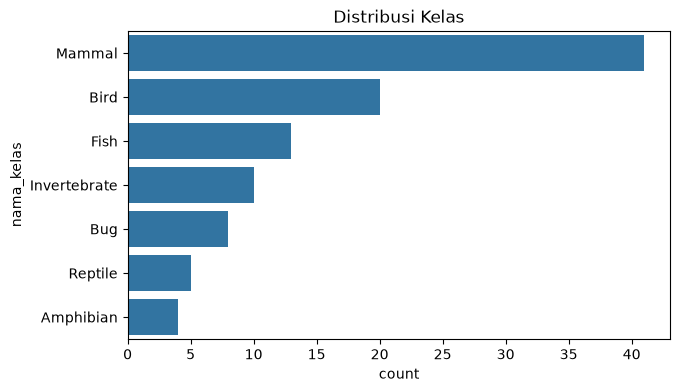

In [4]:
# Distribusi target, diberi nama kelas dari class.csv
peta = dict(zip(kelas["Class_Number"], kelas["Class_Type"]))
zoo["nama_kelas"] = zoo[TARGET].map(peta)

jumlah = zoo["nama_kelas"].value_counts()
print("Jumlah kelas:", zoo[TARGET].nunique())
display(jumlah.to_frame("jumlah").assign(persen=(jumlah / len(zoo) * 100).round(1)))

plt.figure(figsize=(7, 4))
sns.countplot(y="nama_kelas", data=zoo, order=jumlah.index)
plt.title("Distribusi Kelas")
plt.show()

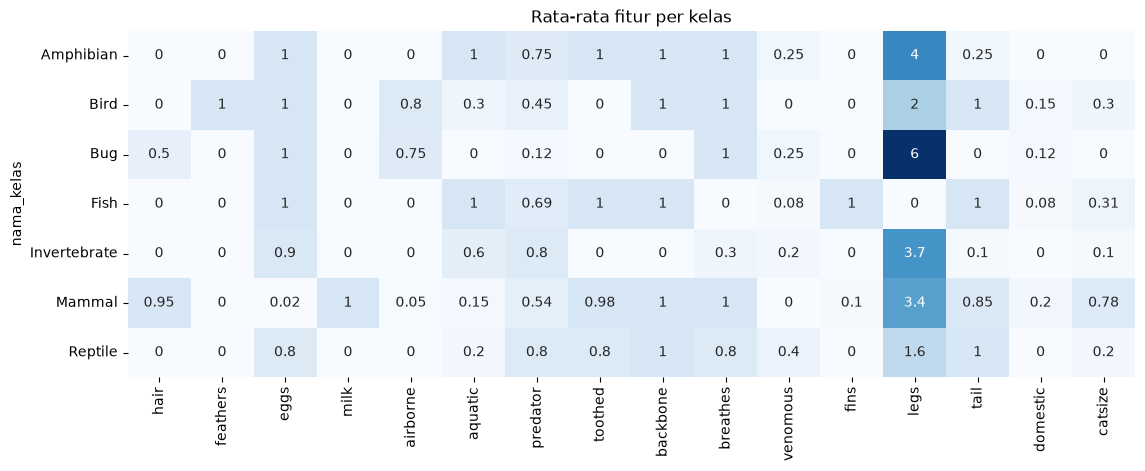

Nilai legs per kelas:


,legs
nama_kelas,
Amphibian,[4]
Bird,[2]
Bug,[6]
Fish,[0]
Invertebrate,"[0, 4, 5, 6, 8]"
Mammal,"[0, 2, 4]"
Reptile,"[0, 4]"


In [5]:
# Rata-rata tiap fitur per kelas (nilai 0-1 untuk fitur biner)
rata = zoo.groupby("nama_kelas")[fitur].mean().round(2)
plt.figure(figsize=(13, 4.5))
sns.heatmap(rata, annot=True, cmap="Blues", cbar=False)
plt.title("Rata-rata fitur per kelas")
plt.show()

print("Nilai legs per kelas:")
display(zoo.groupby("nama_kelas")["legs"].agg(lambda s: sorted(s.unique())).to_frame("legs"))

In [6]:
X = zoo[fitur]
y = zoo[TARGET]
nama_kelas = [peta[k] for k in sorted(y.unique())]   # urutan sesuai angka kelas 1..7

# Kelas terkecil hanya 4 data, jadi test_size 0.3 agar tiap kelas muncul di data test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Jumlah per kelas di data test:", y_test.value_counts().sort_index().to_dict())

Train: (70, 16) | Test: (31, 16)
Jumlah per kelas di data test: {1: 13, 2: 6, 3: 2, 4: 4, 5: 1, 6: 2, 7: 3}


In [7]:
models = {
    "Logistic Regression": Pipeline([("sc", StandardScaler()),
                                     ("clf", LogisticRegression(max_iter=3000))]),
    "KNN": Pipeline([("sc", StandardScaler()),
                     ("clf", KNeighborsClassifier(n_neighbors=5))]),
    "SVM": Pipeline([("sc", StandardScaler()),
                     ("clf", SVC(probability=True, random_state=42))]),
    "Naive Bayes": BernoulliNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
}

# 4 lipatan karena kelas terkecil hanya 4 data (5 lipatan akan memberi peringatan)
cv = RepeatedStratifiedKFold(n_splits=4, n_repeats=5, random_state=42)
scoring = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]

rows = []
for nama, model in models.items():
    hasil = cross_validate(model, X, y, cv=cv, scoring=scoring, n_jobs=-1)
    rows.append({"Model": nama, **{m: hasil[f"test_{m}"].mean() for m in scoring}})

hasil_cv = pd.DataFrame(rows).set_index("Model").round(4).sort_values("f1_macro", ascending=False)
display(hasil_cv)
print("Akurasi jika menebak kelas terbanyak (Mammal):", round((y == 1).mean(), 4))

,accuracy,precision_macro,recall_macro,f1_macro
Model,,,,
Decision Tree,0.9582,0.8732,0.8940,0.8714
Naive Bayes,0.9405,0.8826,0.8818,0.8677
Logistic Regression,0.9602,0.8613,0.8833,0.8673
Random Forest,0.9563,0.8632,0.8798,0.8626
SVM,0.9423,0.8231,0.8494,0.8273
KNN,0.9305,0.8087,0.8319,0.8091
Gradient Boosting,0.9166,0.7993,0.8162,0.7909


Akurasi jika menebak kelas terbanyak (Mammal): 0.4059


In [8]:
fitted, rows = {}, []
for nama, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    fitted[nama] = model
    rows.append({
        "Model": nama,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (macro)": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_test, pred, average="macro", zero_division=0),
    })

hasil_test = pd.DataFrame(rows).set_index("Model").round(4).sort_values("F1 (macro)", ascending=False)
display(hasil_test)

,Accuracy,Precision (macro),Recall (macro),F1 (macro)
Model,,,,
KNN,0.9677,0.9714,0.9286,0.9365
SVM,0.9677,0.9714,0.9286,0.9365
Naive Bayes,0.9677,0.9714,0.9286,0.9365
Gradient Boosting,0.9677,0.9714,0.9286,0.9365
Random Forest,0.9677,0.9714,0.9286,0.9365
Logistic Regression,0.9677,0.9643,0.9286,0.9320
Decision Tree,0.9677,0.9286,0.9286,0.9048


Model terbaik (menurut CV): Decision Tree
              precision    recall  f1-score   support

      Mammal       1.00      1.00      1.00        13
        Bird       1.00      1.00      1.00         6
     Reptile       1.00      0.50      0.67         2
        Fish       1.00      1.00      1.00         4
   Amphibian       0.50      1.00      0.67         1
         Bug       1.00      1.00      1.00         2
Invertebrate       1.00      1.00      1.00         3

    accuracy                           0.97        31
   macro avg       0.93      0.93      0.90        31
weighted avg       0.98      0.97      0.97        31



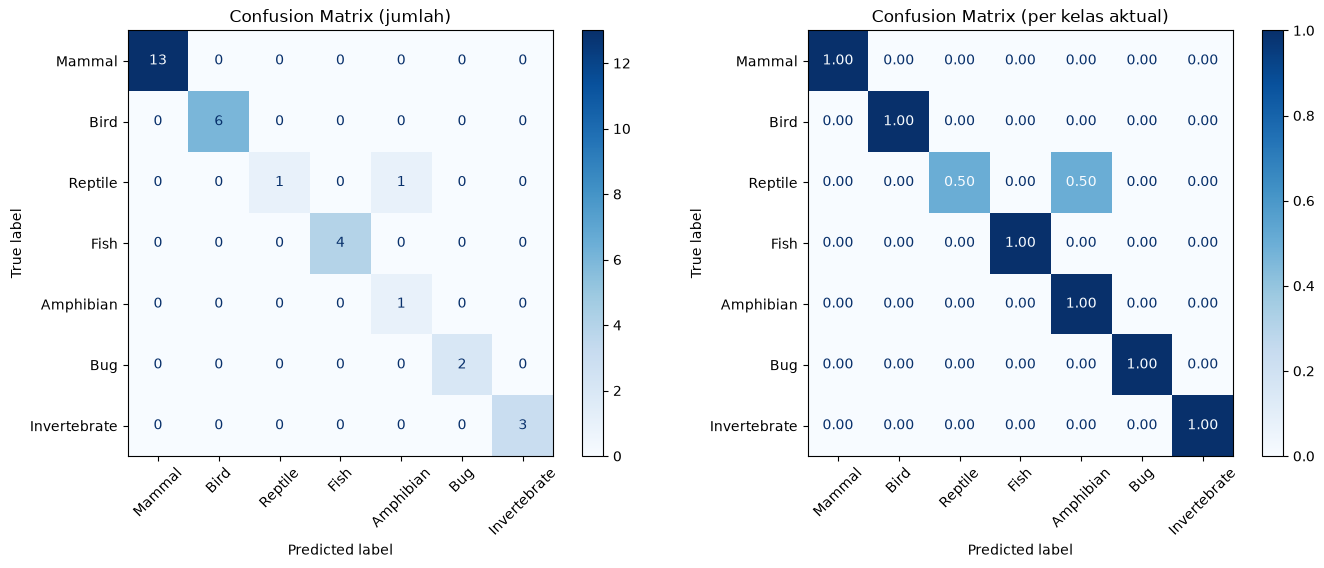

In [9]:
nama_terbaik = hasil_cv.index[0]            # pilih berdasarkan cross-validation, bukan data test
terbaik = fitted[nama_terbaik]
pred = terbaik.predict(X_test)

print("Model terbaik (menurut CV):", nama_terbaik)
print(classification_report(y_test, pred, labels=sorted(y.unique()),
                            target_names=nama_kelas, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=sorted(y.unique()),
                                        display_labels=nama_kelas, cmap="Blues",
                                        ax=axes[0], xticks_rotation=45)
axes[0].set_title("Confusion Matrix (jumlah)")
ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=sorted(y.unique()),
                                        display_labels=nama_kelas, cmap="Blues",
                                        normalize="true", values_format=".2f",
                                        ax=axes[1], xticks_rotation=45)
axes[1].set_title("Confusion Matrix (per kelas aktual)")
plt.tight_layout()
plt.show()

Model: Decision Tree
              precision    recall  f1-score   support

      Mammal       1.00      1.00      1.00        41
        Bird       1.00      1.00      1.00        20
     Reptile       0.75      0.60      0.67         5
        Fish       1.00      1.00      1.00        13
   Amphibian       0.60      0.75      0.67         4
         Bug       0.88      0.88      0.88         8
Invertebrate       0.90      0.90      0.90        10

    accuracy                           0.95       101
   macro avg       0.88      0.88      0.87       101
weighted avg       0.95      0.95      0.95       101



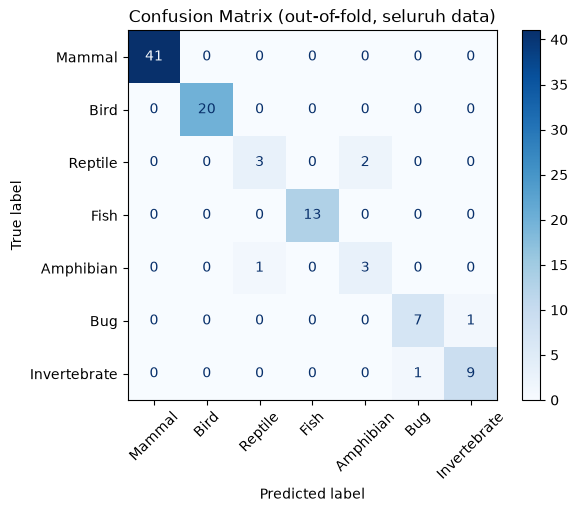

,animal_name,nama_kelas,prediksi
42,ladybird,Bug,Invertebrate
52,newt,Amphibian,Reptile
72,scorpion,Invertebrate,Bug
76,seasnake,Reptile,Amphibian
91,tuatara,Reptile,Amphibian


In [10]:
oof = cross_val_predict(models[nama_terbaik], X, y,
                        cv=StratifiedKFold(n_splits=4, shuffle=True, random_state=42))

print("Model:", nama_terbaik)
print(classification_report(y, oof, target_names=nama_kelas, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y, oof, display_labels=nama_kelas, cmap="Blues",
                                        xticks_rotation=45)
plt.title("Confusion Matrix (out-of-fold, seluruh data)")
plt.show()

# Hewan yang salah ditebak
salah = zoo.loc[oof != y, [NAMA_COL, "nama_kelas"]].copy()
salah["prediksi"] = [peta[k] for k in oof[oof != y]]
display(salah)

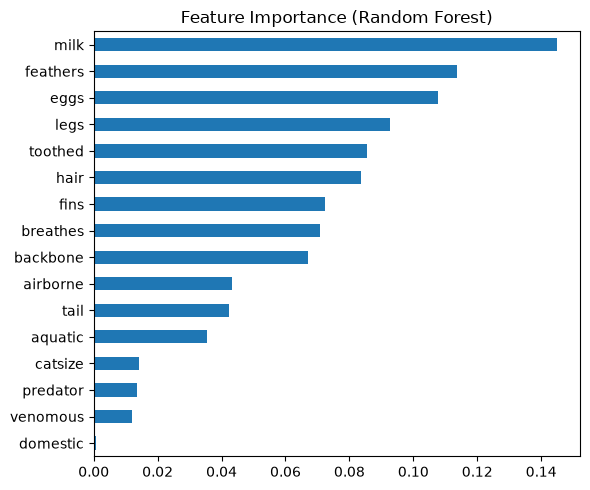

In [11]:
rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(X, y)
penting = pd.Series(rf.feature_importances_, index=fitur).sort_values()

plt.figure(figsize=(6, 5))
penting.plot(kind="barh")
plt.title("Feature Importance (Random Forest)")
plt.tight_layout()
plt.show()

In [12]:
final_model = models[nama_terbaik].fit(X, y)   # latih ulang pada seluruh data

contoh = X.head(5)
hasil = pd.DataFrame({
    "hewan": zoo.loc[contoh.index, NAMA_COL],
    "aktual": zoo.loc[contoh.index, "nama_kelas"],
    "prediksi": [peta[k] for k in final_model.predict(contoh)],
})
display(hasil)

import joblib
joblib.dump({"model": final_model, "fitur": fitur, "peta_kelas": peta}, "model_zoo.pkl")
print("Model tersimpan: model_zoo.pkl")

,hewan,aktual,prediksi
0,aardvark,Mammal,Mammal
1,antelope,Mammal,Mammal
2,bass,Fish,Fish
3,bear,Mammal,Mammal
4,boar,Mammal,Mammal


Model tersimpan: model_zoo.pkl


# README: Dataset Zoo (Klasifikasi Multikelas)

## Ringkasan dataset

| Item | Keterangan |
|---|---|
| File | `zoo.csv` (data latih) dan `class.csv` (kamus nama kelas) |
| Jumlah data | 101 baris pada `zoo.csv`, 7 baris pada `class.csv` |
| Kolom `zoo.csv` | 18 kolom: `animal_name`, 16 fitur, dan 1 target (`class_type`) |
| Fitur | 15 kolom biner 0/1 (misalnya `hair`, `feathers`, `eggs`, `milk`, `airborne`, `aquatic`, `fins`) dan 1 kolom numerik (`legs`) |
| Target | `class_type` (kode 1 sampai 7) |
| Missing value | Tidak ada |
| Duplikat baris | Tidak ada (ada 2 baris bernama `frog`, fiturnya berbeda) |

Dataset ini berisi ciri-ciri fisik hewan (berambut, berbulu, bertelur, menyusui, jumlah kaki, dan sebagainya) beserta kelas hewannya.

## Mengapa ini termasuk klasifikasi multikelas

1. **Pembelajaran terawasi (supervised).** Setiap hewan sudah punya label `class_type`.
2. **Targetnya kategorikal, bukan angka kontinu.** Angka 1 sampai 7 pada `class_type` hanyalah kode untuk nama kelas, bukan besaran atau urutan. Arti kodenya ada di `class.csv`. Karena itu masalahnya bukan regresi.
3. **Targetnya punya lebih dari dua kelas.** Ada tepat 7 kelas, sehingga bukan klasifikasi biner.

| Kode | Kelas | Jumlah | Persentase |
|---|---|---|---|
| 1 | Mammal | 41 | 40,6% |
| 2 | Bird | 20 | 19,8% |
| 4 | Fish | 13 | 12,9% |
| 7 | Invertebrate | 10 | 9,9% |
| 6 | Bug | 8 | 7,9% |
| 3 | Reptile | 5 | 5,0% |
| 5 | Amphibian | 4 | 4,0% |

4. **Setiap data hanya punya satu kelas (single-label).** Satu hewan hanya masuk ke satu kelas, jadi ini bukan klasifikasi multi-label. Tidak ada pola fitur yang sama tetapi berlabel berbeda.
5. **Keluaran model berupa satu pilihan dari tujuh kelas.**

## Karakteristik penting

- **Kelas sangat tidak seimbang.** Mammal 40,6% sedangkan Amphibian hanya 4 data dan Reptile 5 data. Menebak semua Mammal sudah memberi akurasi 40,6%. Karena itu fokus pada F1 macro dan laporan per kelas, bukan accuracy saja.
- **Cara validasi menyesuaikan data kecil.** Kelas terkecil hanya punya 4 anggota, sehingga cross-validation memakai 4 lipatan (dengan pengulangan), dan data test dibuat 30% agar tiap kelas muncul di data test.
- **`class.csv` hanya kamus.** Isinya memetakan kode kelas ke nama dan mendaftar nama hewan per kelas. File ini dipakai untuk memberi nama pada kelas, bukan sebagai fitur.
- **`animal_name` tidak dipakai sebagai fitur.** Memasukkannya membuat model menghafal nama, bukan belajar dari ciri hewan.
- **Fitur terpenting:** `milk`, `feathers`, `eggs`, `legs`, dan `toothed`.
- **Kelas tersulit adalah Reptile.** Anggotanya beragam (ular tanpa kaki dan kura-kura berkaki empat) dan jumlahnya hanya 5, sehingga sering tertukar dengan Bird, Fish, atau Amphibian.

## Hasil baseline (4-fold stratified cross-validation, diulang 5 kali)

| Model | Accuracy | F1 macro |
|---|---|---|
| Decision Tree | 0,958 | 0,871 |
| Logistic Regression | 0,960 | 0,867 |
| Naive Bayes | 0,941 | 0,868 |
| Random Forest | 0,956 | 0,863 |
| SVM | 0,942 | 0,827 |
| KNN | 0,931 | 0,809 |
| Gradient Boosting | 0,917 | 0,791 |

Selisih antara accuracy (sekitar 0,95) dan F1 macro (sekitar 0,86) muncul karena ada kelas kecil yang sulit. Pada Random Forest, kelas Reptile hanya mencapai F1 0,57 dengan recall 0,40 (2 dari 5 benar), sedangkan Mammal, Bird, Fish, Bug, dan Invertebrate hampir sempurna. Pada data sekecil ini, selisih antar model tidak bermakna.

## LINK DATASET

[Zoo Animal Classification] (https://www.kaggle.com/datasets/uciml/zoo-animal-classification)